# HW2 — Visualization: object detection models

We analyze validation predictions, localization and classification errors, object-scale effects, and learned representations for **Faster R-CNN, RetinaNet, YOLO11, and RT-DETR**. We compare the available official-validation measurements, inspect saved evaluation figures for anchor-based models, and run fresh inference for YOLO11 and RT-DETR. We log the generated evidence to **Weights & Biases**.

**Reproducibility:** We run this notebook from the repository `notebooks/` directory. YOLO11 and RT-DETR inference requires the saved `.pt` weights and validation images under `artifacts/`. For Faster R-CNN and RetinaNet, we use the saved outputs in their executed experiment notebooks. Training histories are plotted only when genuine per-epoch/per-step records exist.

## 0. Environment and inputs

We load the dataset, detector weights, and executed experiment notebooks.

In [ ]:
# Uncomment once if dependencies are not installed, then restart the kernel.
# %pip install -q ultralytics wandb opencv-python pillow scikit-learn pandas matplotlib pyyaml nbformat

In [6]:

from pathlib import Path
import os
import json
import math
import re
import io
import warnings
import base64

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import wandb
import yaml
import nbformat

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from ultralytics import YOLO, RTDETR


def find_repo():
    here = Path.cwd().resolve()

    for p in (here, *here.parents):
        if (p / "notebooks").is_dir() and (p / "configs").is_dir():
            return p

    raise FileNotFoundError(
        "Open this notebook inside cv-object-detection/notebooks/."
    )


ROOT = find_repo()

ART = ROOT / "artifacts"
WEIGHTS = ART / "weights"

VAL = ART / "visualization"
IMAGE_DIR = VAL / "images"
ANN = VAL / "annotations.json"

OUT = ART / "visualization"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Validation data and trained detectors

We use the same COCO annotations and image sample for both models that can be re-evaluated directly.

In [15]:

MODEL_SPECS = {
    "YOLO11": {
        "path": WEIGHTS / "yolo11_best.pt",
        "kind": "yolo",
    },
    "RT-DETR": {
        "path": WEIGHTS / "rtdetr_best.pt",
        "kind": "rtdetr",
    },
}

OTHER_CHECKPOINTS = {
    "Faster R-CNN": WEIGHTS / "faster_rcnn_best.pt",
    "RetinaNet": WEIGHTS / "retinanet_best.pt",
}

required_paths = [
    ANN,
    IMAGE_DIR,
    *[v["path"] for v in MODEL_SPECS.values()],
]

missing = [str(p) for p in required_paths if not p.exists()]

print("Files available:")

for p in required_paths:
    print((" OK " if p.exists() else "MISSING"), p)

for name, p in OTHER_CHECKPOINTS.items():
    print(name, "available" if p.exists() else "not found", p)

if missing:
    raise FileNotFoundError(
        "Required files missing. Correct paths before continuing:\n"
        + "\n".join(missing)
    )

gt = json.loads(ANN.read_text(encoding="utf-8"))

assert all(
    k in gt for k in ("images", "annotations", "categories")
), "annotations.json must be COCO format"

by_id = {int(x["id"]): x for x in gt["images"]}
cats = {int(x["id"]): x["name"] for x in gt["categories"]}

gt_by_image = {}

for a in gt["annotations"]:
    if a.get("iscrowd", 0):
        continue

    gt_by_image.setdefault(int(a["image_id"]), []).append(a)

def resolve_image(info):
    fname = Path(info["file_name"])
    parts = fname.parts

    candidates = [
        VAL / fname,
        IMAGE_DIR / Path(*parts[1:]) if parts[0] == "images" else IMAGE_DIR / fname,
    ]

    for path in candidates:
        if path.is_file():
            return path

    return None


available = [
    (iid, resolve_image(info))
    for iid, info in by_id.items()
]

available = [
    (iid, p)
    for iid, p in available
    if p is not None
]

if not available:
    raise FileNotFoundError(
        "No COCO images found. Check image file_name paths."
    )

available = sorted(available, key=lambda x: x[0])

chosen = [
    available[i]
    for i in np.sort(
        rng.choice(
            len(available),
            size=min(MAX_IMAGES, len(available)),
            replace=False,
        )
    )
]

print(
    f"COCO images: {len(by_id)}; "
    f"available: {len(available)}; "
    f"selected: {len(chosen)}"
)

print("Categories:", cats)

Files available:
 OK  D:\UCU\ai\hw2\cv-object-detection\artifacts\visualization\annotations.json
 OK  D:\UCU\ai\hw2\cv-object-detection\artifacts\visualization\images
 OK  D:\UCU\ai\hw2\cv-object-detection\artifacts\weights\yolo11_best.pt
 OK  D:\UCU\ai\hw2\cv-object-detection\artifacts\weights\rtdetr_best.pt
Faster R-CNN available D:\UCU\ai\hw2\cv-object-detection\artifacts\weights\faster_rcnn_best.pt
RetinaNet available D:\UCU\ai\hw2\cv-object-detection\artifacts\weights\retinanet_best.pt
COCO images: 24201; available: 24201; selected: 30
Categories: {1: 'person', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'}


In [16]:

MODELS = {}

for name, spec in MODEL_SPECS.items():
    cls = YOLO if spec["kind"] == "yolo" else RTDETR
    MODELS[name] = cls(str(spec["path"]))
    print("Loaded", name, "from", spec["path"].name)


def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    return inter / (area_a + area_b - inter + 1e-9)


def gt_boxes(image_id):
    return [
        {
            "box": np.array(
                [
                    a["bbox"][0],
                    a["bbox"][1],
                    a["bbox"][0] + a["bbox"][2],
                    a["bbox"][1] + a["bbox"][3],
                ],
                dtype=float,
            ),
            "category_id": int(a["category_id"]),
        }
        for a in gt_by_image.get(image_id, [])
    ]


def class_id_for_prediction(cls_index):
    # Dataset class indices are 0-based; COCO annotation
    # category ids may not be contiguous.
    # This competition's annotations use 1..8;
    # assert this rather than silently mislabel.
    return int(cls_index) + 1


assert sorted(cats) == list(range(1, len(cats) + 1)), (
    "Adapt class_id_for_prediction to your dataset category mapping."
)


def match_image(dets, gts, iou_threshold=0.5):
    # Highest confidence predictions match at most
    # one same-class ground truth.
    matched = set()
    out = []

    for d in sorted(dets, key=lambda x: -x["score"]):
        candidates = [
            (iou_xyxy(d["box"], g["box"]), j)
            for j, g in enumerate(gts)
            if j not in matched
            and g["category_id"] == d["category_id"]
        ]

        score, j = max(candidates, default=(0.0, -1))
        label = "TP" if score >= iou_threshold else "FP"

        if label == "TP":
            matched.add(j)

        out.append(
            {
                **d,
                "status": label,
                "matched_iou": float(score) if label == "TP" else 0.0,
            }
        )

    misses = [
        g
        for j, g in enumerate(gts)
        if j not in matched
    ]

    return out, misses


all_rows = []
records = {}

for name, model in MODELS.items():
    records[name] = {}

    for image_id, path in chosen:
        res = model.predict(
            str(path),
            conf=CONF,
            iou=0.7,
            max_det=300,
            imgsz=1152,
            device=DEVICE,
            verbose=False,
        )[0]

        boxes = res.boxes.xyxy.cpu().numpy()
        scores = res.boxes.conf.cpu().numpy()
        classes = res.boxes.cls.cpu().numpy().astype(int)

        dets = [
            {
                "box": b,
                "score": float(s),
                "category_id": class_id_for_prediction(c),
            }
            for b, s, c in zip(boxes, scores, classes)
        ]

        labeled, misses = match_image(
            dets,
            gt_boxes(image_id),
        )

        records[name][image_id] = {
            "path": path,
            "detections": labeled,
            "misses": misses,
        }

        for d in labeled:
            all_rows.append(
                {
                    "model": name,
                    "image_id": image_id,
                    "category_id": d["category_id"],
                    "class": cats[d["category_id"]],
                    "score": d["score"],
                    "status": d["status"],
                    "area": float(
                        np.prod(
                            np.maximum(
                                0,
                                d["box"][2:] - d["box"][:2],
                            )
                        )
                    ),
                    "iou": d["matched_iou"],
                }
            )

        for g in misses:
            all_rows.append(
                {
                    "model": name,
                    "image_id": image_id,
                    "category_id": g["category_id"],
                    "class": cats[g["category_id"]],
                    "score": np.nan,
                    "status": "FN",
                    "area": float(
                        np.prod(
                            np.maximum(
                                0,
                                g["box"][2:] - g["box"][:2],
                            )
                        )
                    ),
                    "iou": np.nan,
                }
            )

    print(
        name, ":", len(records[name]),
        "validation images processed"
    )

df = pd.DataFrame(all_rows)

if df.empty:
    raise RuntimeError(
        "No objects or predictions found in selected images."
    )

display(
    df.groupby(["model", "status"])
    .size()
    .unstack(fill_value=0)
)

df.to_csv(
    OUT / "per_object_diagnostics.csv",
    index=False,
)

Loaded YOLO11 from yolo11_best.pt
Loaded RT-DETR from rtdetr_best.pt
YOLO11 : 30 validation images processed
RT-DETR : 30 validation images processed


status,FN,FP,TP
model,,,
RT-DETR,182,2925,1174
YOLO11,251,894,1105


In [17]:

from collections import Counter

filenames = [
    Path(info["file_name"]).name
    for info in gt["images"]
]

counts = Counter(filenames)

duplicates = {
    name: count
    for name, count in counts.items()
    if count > 1
}

print("Total COCO images:", len(filenames))
print("Unique filenames:", len(counts))
print("Duplicate filenames:", len(duplicates))

for name, count in list(duplicates.items())[:15]:
    print(name, count)


Total COCO images: 24201
Unique filenames: 1424
Duplicate filenames: 1255
0000001.jpg 56
0000002.jpg 56
0000003.jpg 56
0000004.jpg 56
0000005.jpg 56
0000006.jpg 56
0000007.jpg 56
0000008.jpg 56
0000009.jpg 56
0000010.jpg 56
0000011.jpg 56
0000012.jpg 56
0000013.jpg 56
0000014.jpg 56
0000015.jpg 56


## 2. Bounding-box predictions and error matching

We match predicted and ground-truth boxes by class at IoU ≥ 0.5. This is a diagnostic matching protocol, **not** official COCO mAP evaluation.

In [18]:

PRED_DIR = ART / "predictions"
PRED_DIR.mkdir(exist_ok=True, parents=True)

OTHER_PRED_FILES = {
    "Faster R-CNN": PRED_DIR / "faster_rcnn.json",
    "RetinaNet": PRED_DIR / "retinanet.json",
}

for name, pred_path in OTHER_PRED_FILES.items():
    if not pred_path.exists():
        print("Missing", name, "predictions:", pred_path)
        continue

    raw = json.loads(pred_path.read_text(encoding="utf-8"))

    if isinstance(raw, dict) and "detections" in raw:
        raw = raw["detections"]

    by_image = {}

    for item in raw:
        by_image.setdefault(
            int(item["image_id"]), []
        ).append(item)

    records[name] = {}

    for image_id, path in chosen:
        dets = []

        for item in by_image.get(image_id, []):
            x, y, w, h = map(float, item["bbox"])

            if float(item["score"]) < CONF:
                continue

            dets.append(
                {
                    "box": np.array([x, y, x + w, y + h]),
                    "score": float(item["score"]),
                    "category_id": int(item["category_id"]),
                }
            )

        labeled, misses = match_image(
            dets,
            gt_boxes(image_id),
        )

        records[name][image_id] = {
            "path": path,
            "detections": labeled,
            "misses": misses,
        }

        for d in labeled:
            all_rows.append(
                {
                    "model": name,
                    "image_id": image_id,
                    "category_id": d["category_id"],
                    "class": cats[d["category_id"]],
                    "score": d["score"],
                    "status": d["status"],
                    "area": float(
                        np.prod(
                            np.maximum(
                                0,
                                d["box"][2:] - d["box"][:2],
                            )
                        )
                    ),
                    "iou": d["matched_iou"],
                }
            )

        for g in misses:
            all_rows.append(
                {
                    "model": name,
                    "image_id": image_id,
                    "category_id": g["category_id"],
                    "class": cats[g["category_id"]],
                    "score": np.nan,
                    "status": "FN",
                    "area": float(
                        np.prod(
                            np.maximum(
                                0,
                                g["box"][2:] - g["box"][:2],
                            )
                        )
                    ),
                    "iou": np.nan,
                }
            )

    print(
        "Loaded",
        name,
        "predictions for",
        len(records[name]),
        "images",
    )

df = pd.DataFrame(all_rows)

df.to_csv(
    OUT / "per_object_diagnostics.csv",
    index=False,
)

Missing Faster R-CNN predictions: D:\UCU\ai\hw2\cv-object-detection\artifacts\predictions\faster_rcnn.json
Missing RetinaNet predictions: D:\UCU\ai\hw2\cv-object-detection\artifacts\predictions\retinanet.json


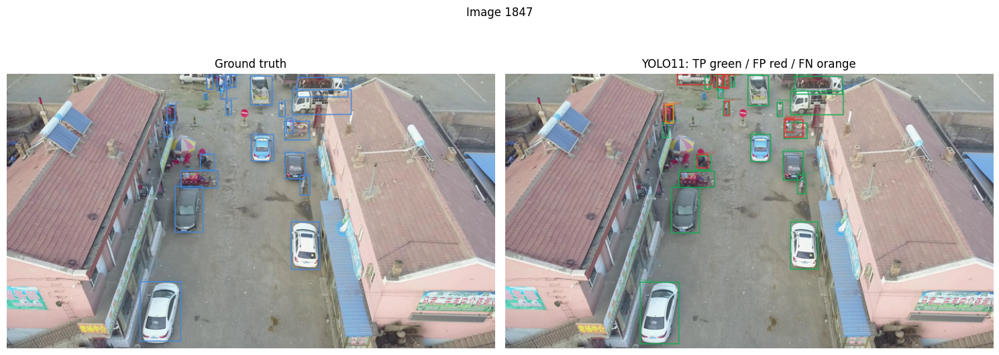

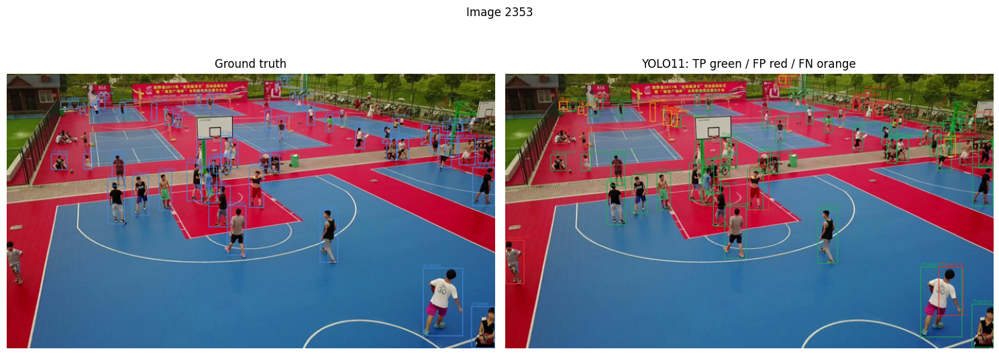

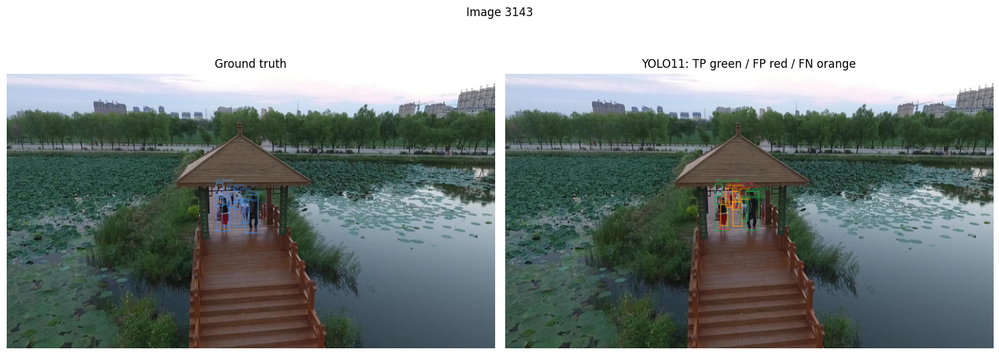

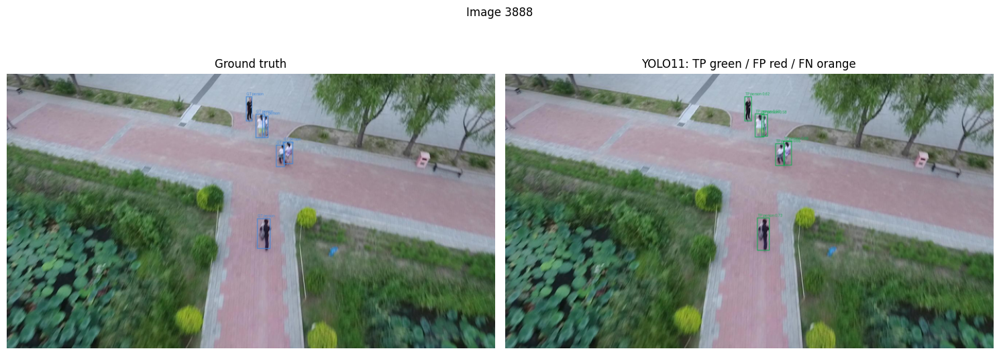

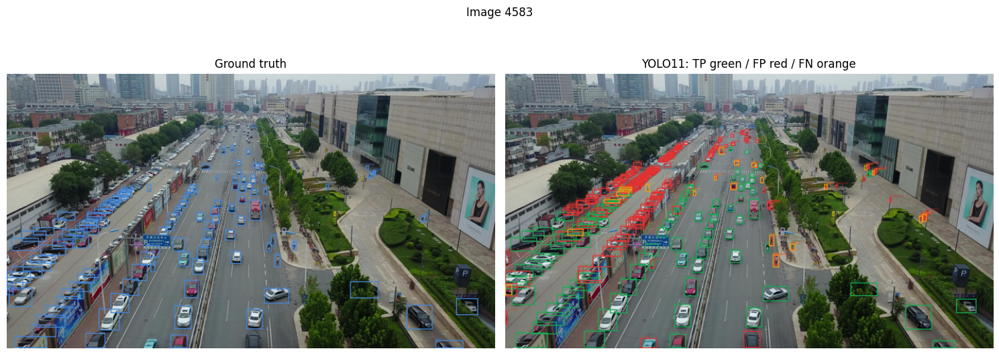

...

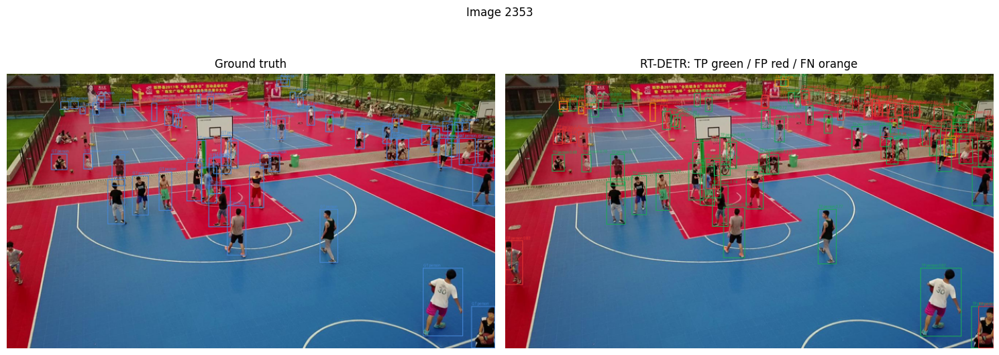

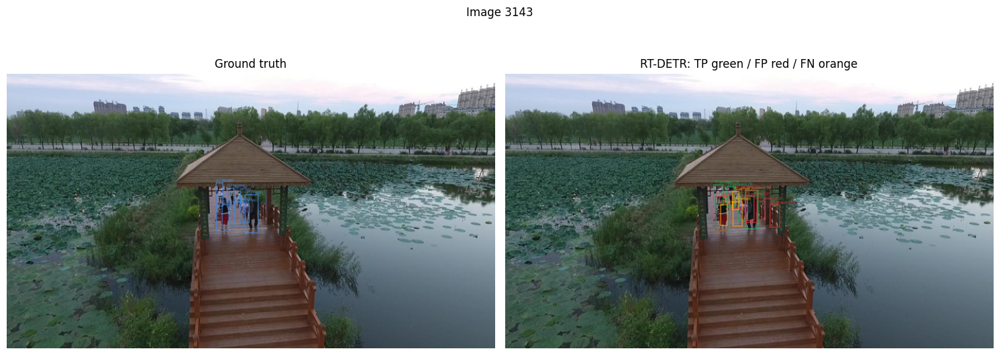

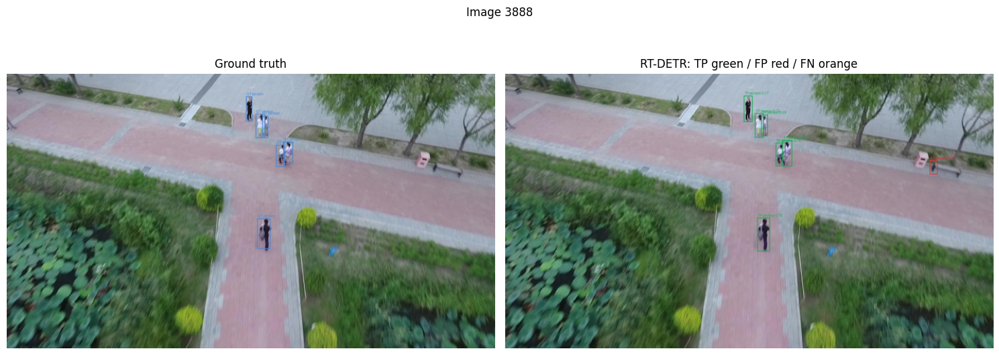

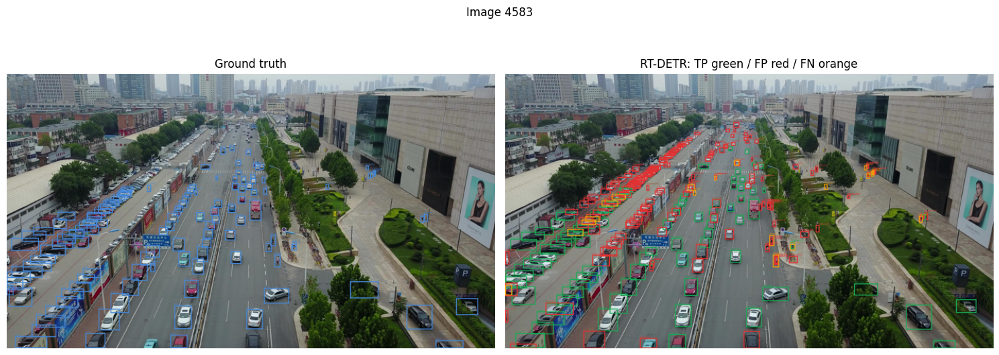

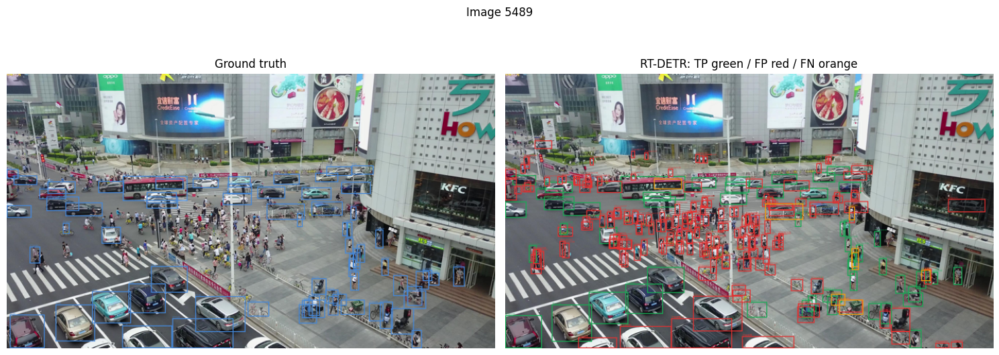

Generated 12 real bounding-box visualizations.


In [19]:

def draw_boxes(img, items, kind):
    canvas = img.copy().convert("RGB")
    d = ImageDraw.Draw(canvas)

    for it in items:
        b = it["box"]
        label = it.get("status", "GT")

        color = {
            "TP": "#19aa55",
            "FP": "#e13232",
            "FN": "#f59e0b",
            "GT": "#4587d7",
        }[label]

        d.rectangle(
            tuple(map(float, b)),
            outline=color,
            width=max(2, img.width // 450),
        )

        name = cats[it["category_id"]]
        score = "" if "score" not in it else f" {it['score']:.2f}"

        d.text(
            (float(b[0]) + 2, max(0, float(b[1]) - 13)),
            f"{label} {name}{score}",
            fill=color,
        )

    return canvas


overlay_paths = []

for name in records:
    for image_id in list(records[name])[:min(6, len(chosen))]:
        rec = records[name][image_id]

        img = Image.open(rec["path"]).convert("RGB")

        left = draw_boxes(
            img,
            gt_boxes(image_id),
            "gt",
        )

        right = draw_boxes(
            img,
            rec["detections"] + [
                {**g, "status": "FN"}
                for g in rec["misses"]
            ],
            "pred",
        )

        w = 700
        h = round(img.height * w / img.width)

        left = left.resize((w, h))
        right = right.resize((w, h))

        fig, axs = plt.subplots(1, 2, figsize=(15, 6))

        axs[0].imshow(left)
        axs[0].set_title("Ground truth")
        axs[0].axis("off")

        axs[1].imshow(right)
        axs[1].set_title(
            f"{name}: TP green / FP red / FN orange"
        )
        axs[1].axis("off")

        fig.suptitle(f"Image {image_id}")
        fig.tight_layout()

        output = OUT / (
            f"boxes_{re.sub(r'[^a-z0-9]+', '_', name.lower())}"
            f"_{image_id}.png"
        )

        fig.savefig(
            output,
            dpi=120,
            bbox_inches="tight",
        )

        display(fig)
        plt.close(fig)

        overlay_paths.append((name, output))

print(
    "Generated",
    len(overlay_paths),
    "real bounding-box visualizations.",
)

## 3. Failure patterns by class and object size

We compare true positives, false positives, and false negatives by category and COCO box-size group.

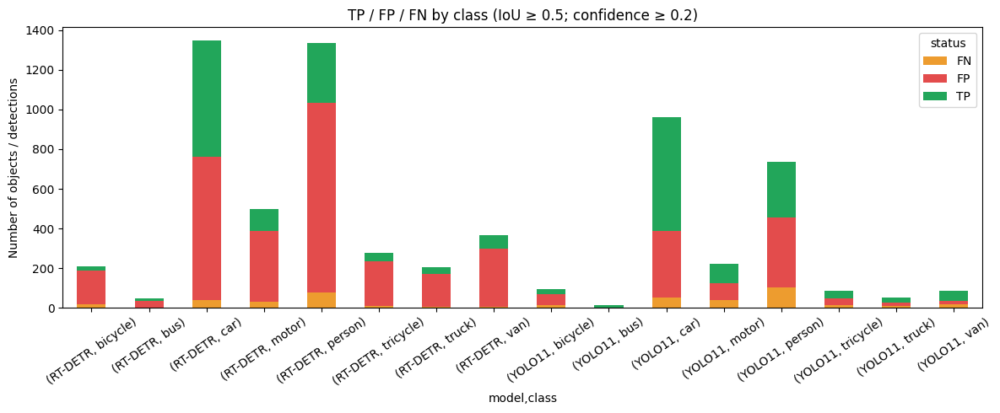

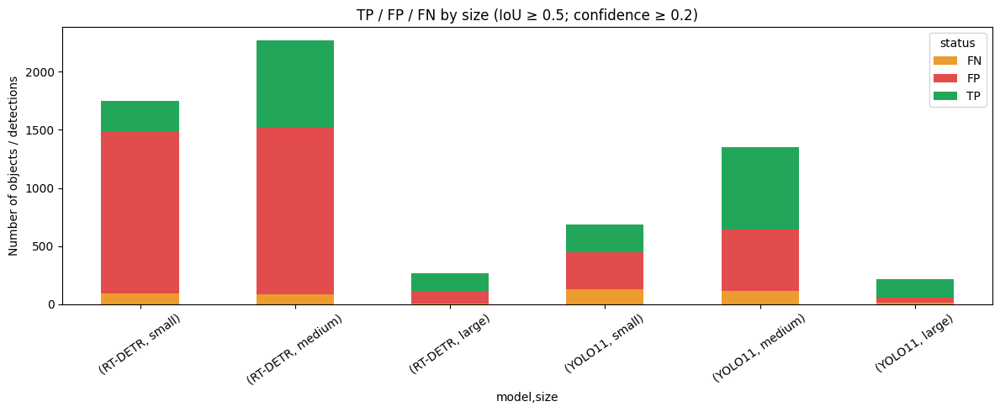

In [20]:

df["size"] = pd.cut(
    df["area"],
    bins=[-1, 32**2, 96**2, float("inf")],
    labels=["small", "medium", "large"],
)

for grouping in ["class", "size"]:
    fig, ax = plt.subplots(figsize=(12, 5))

    grouped = (
        df.groupby(
            ["model", grouping, "status"],
            observed=True,
        )
        .size()
        .unstack(fill_value=0)
    )

    grouped.plot.bar(
        stacked=True,
        ax=ax,
        color={
            "TP": "#22a65a",
            "FP": "#e34c4c",
            "FN": "#ed9c2f",
        },
    )

    ax.set_title(
        f"TP / FP / FN by {grouping} "
        f"(IoU ≥ 0.5; confidence ≥ {CONF})"
    )
    ax.set_ylabel("Number of objects / detections")
    ax.tick_params(axis="x", rotation=35)

    fig.tight_layout()

    path = OUT / f"failure_by_{grouping}.png"
    fig.savefig(path, dpi=140)

    display(fig)
    plt.close(fig)


## 4. Learned YOLO11 feature representations

We pool intermediate convolutional feature-map vectors over predicted boxes, then visualize them with PCA and t-SNE. The spatial mapping approximates letterbox preprocessing, so these embeddings are diagnostic rather than exact RoIAlign features.

Hooking layer 22 C3k2


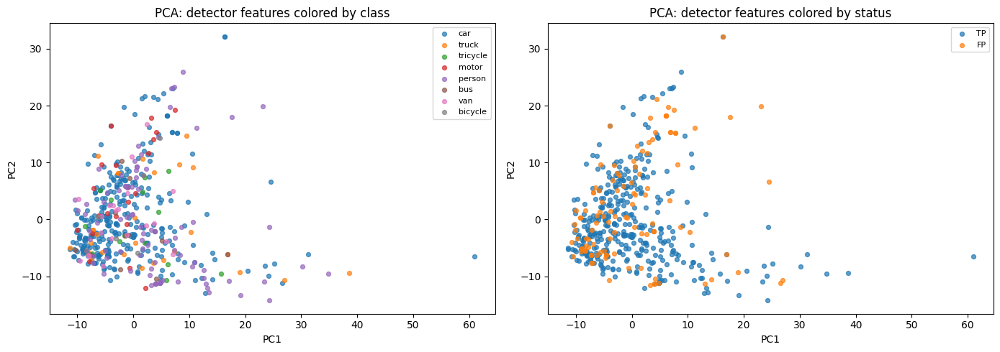

Extracted 493 real detector feature vectors of dimension 512


In [21]:

yolo = MODELS["YOLO11"]

backend = yolo.predictor.model
net = backend.model
layers = list(net.model)

candidates = [
    (i, layer)
    for i, layer in enumerate(layers[:-1])
    if any(
        k in type(layer).__name__.lower()
        for k in ("c3", "c2", "conv", "c2psa")
    )
]

if not candidates:
    raise RuntimeError(
        "No convolutional feature layer found for embeddings."
    )

layer_index, layer = candidates[-1]

print("Hooking layer", layer_index, type(layer).__name__)

feature_rows = []
feature_vectors = []

for image_id, path in chosen[:min(20, len(chosen))]:
    cache = {}

    def hook(module, args, output):
        if torch.is_tensor(output) and output.ndim == 4:
            cache["features"] = output.detach().float().cpu()

    handle = layer.register_forward_hook(hook)

    try:
        _ = yolo.predict(
            str(path),
            imgsz=1152,
            device=DEVICE,
            conf=CONF,
            verbose=False,
        )
    finally:
        handle.remove()

    if "features" not in cache:
        raise RuntimeError(
            f"No 4D features captured from inference layer {layer_index}. "
            "Inspect yolo.predictor.model.model.model and choose a convolutional layer."
        )

    feat = cache["features"][0].numpy()
    _, fh, fw = feat.shape

    im = Image.open(path)
    iw, ih = im.size

    for d in records["YOLO11"][image_id]["detections"][:MAX_BOXES_PER_IMAGE]:
        x1, y1, x2, y2 = d["box"]

        inp = yolo.predictor
        tensor = getattr(inp, "im", None)

        if (
            tensor is not None
            and hasattr(tensor, "shape")
            and len(tensor.shape) == 4
        ):
            net_h, net_w = (
                int(tensor.shape[-2]),
                int(tensor.shape[-1]),
            )
        else:
            net_h, net_w = 1152, 1152

        gain = min(net_w / iw, net_h / ih)
        pad_x = (net_w - iw * gain) / 2
        pad_y = (net_h - ih * gain) / 2

        a = max(
            0,
            min(fw - 1, int((x1 * gain + pad_x) / net_w * fw)),
        )
        b = max(
            0,
            min(fh - 1, int((y1 * gain + pad_y) / net_h * fh)),
        )
        c = max(
            a + 1,
            min(
                fw,
                int(math.ceil((x2 * gain + pad_x) / net_w * fw)),
            ),
        )
        e = max(
            b + 1,
            min(
                fh,
                int(math.ceil((y2 * gain + pad_y) / net_h * fh)),
            ),
        )

        region = feat[:, b:e, a:c]

        if region.size == 0:
            continue

        feature_vectors.append(region.mean(axis=(1, 2)))

        feature_rows.append(
            {
                "image_id": image_id,
                "class": cats[d["category_id"]],
                "status": d["status"],
                "area": float((x2 - x1) * (y2 - y1)),
            }
        )

if len(feature_vectors) < 4:
    raise RuntimeError(
        "Not enough detected objects for embeddings. "
        "Increase MAX_IMAGES or lower CONF."
    )

X = np.stack(feature_vectors)
meta = pd.DataFrame(feature_rows)

X = np.nan_to_num(X)
X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-6)

pca = PCA(
    n_components=2,
    random_state=SEED,
).fit_transform(X)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for key, ax in [
    ("class", axs[0]),
    ("status", axs[1]),
]:
    for value in meta[key].unique():
        mask = (meta[key] == value).to_numpy()

        ax.scatter(
            pca[mask, 0],
            pca[mask, 1],
            s=18,
            alpha=0.7,
            label=str(value),
        )

    ax.legend(fontsize=8, loc="best")
    ax.set_title(f"PCA: detector features colored by {key}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

fig.tight_layout()

pca_path = OUT / "feature_pca.png"

fig.savefig(pca_path, dpi=150)
display(fig)
plt.close(fig)

print(
    "Extracted",
    len(X),
    "real detector feature vectors of dimension",
    X.shape[1],
)

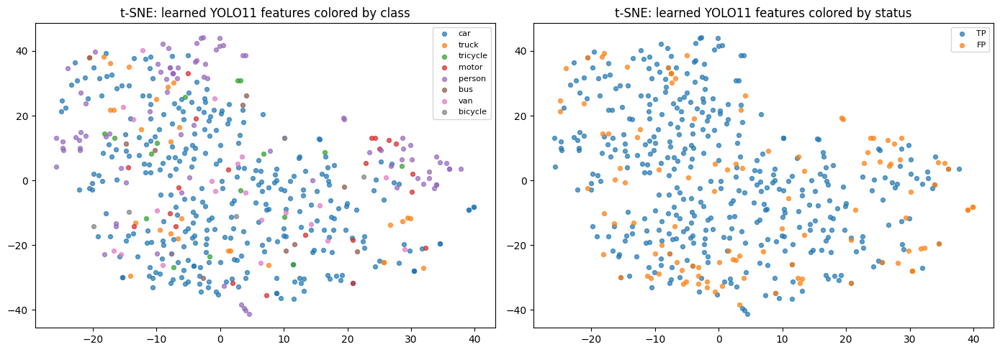

In [22]:

if len(X) >= 6:
    perplexity = min(30, max(2, (len(X) - 1) // 3))

    z = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=SEED,
        init="pca",
        learning_rate="auto",
    ).fit_transform(X)

    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    for key, ax in [
        ("class", axs[0]),
        ("status", axs[1]),
    ]:
        for value in meta[key].unique():
            mask = (meta[key] == value).to_numpy()

            ax.scatter(
                z[mask, 0],
                z[mask, 1],
                s=18,
                alpha=0.7,
                label=str(value),
            )

        ax.legend(fontsize=8)
        ax.set_title(
            f"t-SNE: learned YOLO11 features colored by {key}"
        )

    fig.tight_layout()

    tsne_path = OUT / "feature_tsne.png"

    fig.savefig(tsne_path, dpi=150)
    display(fig)
    plt.close(fig)

else:
    tsne_path = None

meta.to_csv(
    OUT / "feature_metadata.csv",
    index=False,
)

## 5. Anchor-based model evidence

We inspect saved evaluation figures from the executed Faster R-CNN and RetinaNet notebooks and compare their recorded official-validation metrics. We do not treat fold-level comparisons as epoch-by-epoch training histories.

In [23]:

ANCHOR_OUT = OUT / "anchor_based"
ANCHOR_OUT.mkdir(parents=True, exist_ok=True)

for name, path in SRC.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Expected executed experiment notebook: {path}"
        )

print(
    "Anchor-based experiment notebooks:",
    *[p.name for p in SRC.values()],
    sep="\n - ",
)

Anchor-based experiment notebooks:
 - 02-faster-cnn.ipynb
 - 03_retinanet.ipynb
 - 10_anchor_based_comparison.ipynb


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Faster R-CNN saved figures: 3


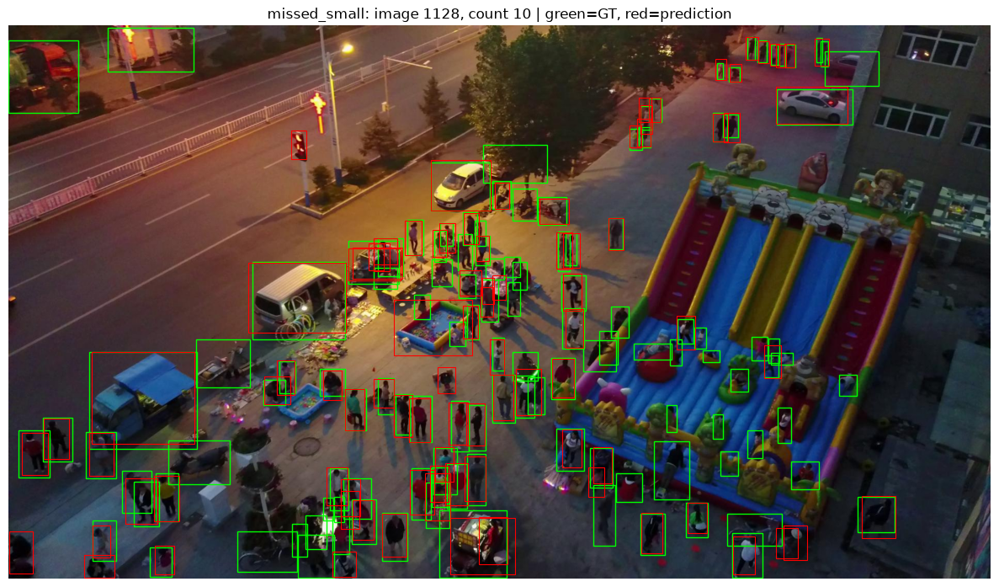

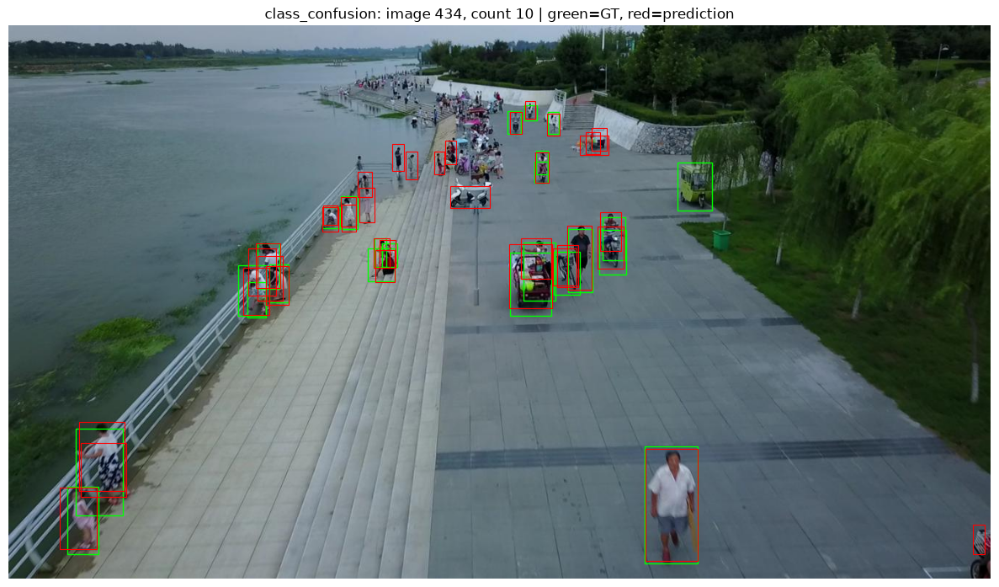

RetinaNet saved figures: 3


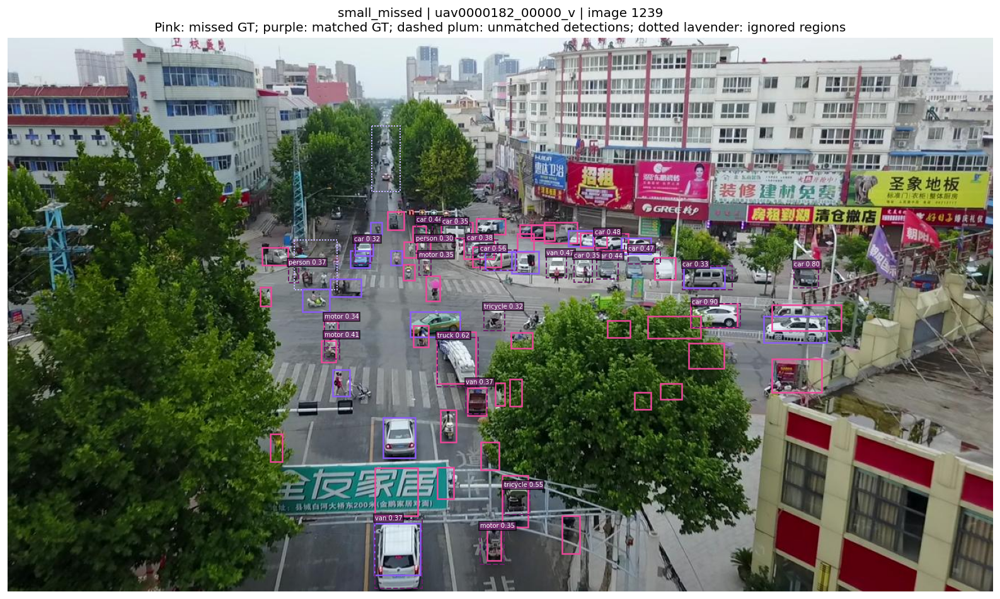

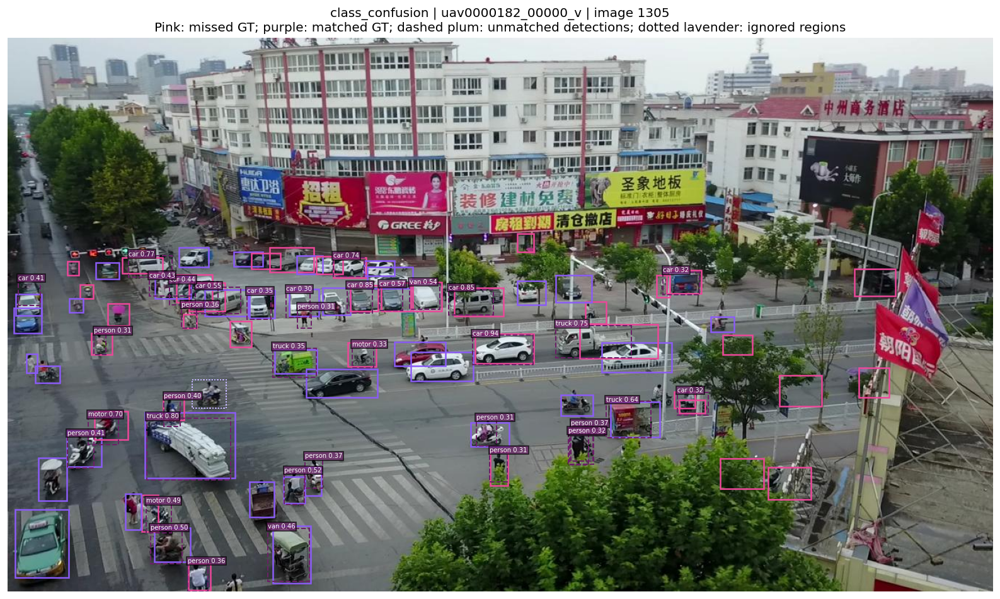

In [24]:

SOURCE_CELLS = {
    "Faster R-CNN": [45],
    "RetinaNet": [53],
}

extracted = {}

for name, indices in SOURCE_CELLS.items():
    notebook = nbformat.read(SRC[name], as_version=4)
    extracted[name] = []

    for ci in indices:
        if ci >= len(notebook.cells):
            continue

        for oi, output in enumerate(
            notebook.cells[ci].get("outputs", [])
        ):
            data = output.get("data", {})

            if "image/png" not in data:
                continue

            raw = base64.b64decode(data["image/png"])

            try:
                im = Image.open(io.BytesIO(raw))
                im.verify()
            except Exception:
                continue

            path = ANCHOR_OUT / (
                f'{name.lower().replace(" ", "_").replace("-", "_")}'
                f"_source_cell{ci}_output{oi}.png"
            )

            path.write_bytes(raw)
            extracted[name].append((path, ci, oi))

    print(name, "saved figures:", len(extracted[name]))

    for path, _, _ in extracted[name][:2]:
        display(Image.open(path))

,candidate,model,mAP,AP50,AP_small,AP_medium,AP_large
0,Faster R-CNN baseline,Faster R-CNN,0.168492,0.343421,0.065114,0.164735,0.319328
1,Faster R-CNN tuned,Faster R-CNN,0.173837,0.350219,0.074241,0.168660,0.319824
2,RetinaNet baseline,RetinaNet,0.151721,0.302021,0.052879,0.158991,0.265586
3,RetinaNet smaller anchors,RetinaNet,0.151295,0.334956,0.069745,0.141452,0.254822


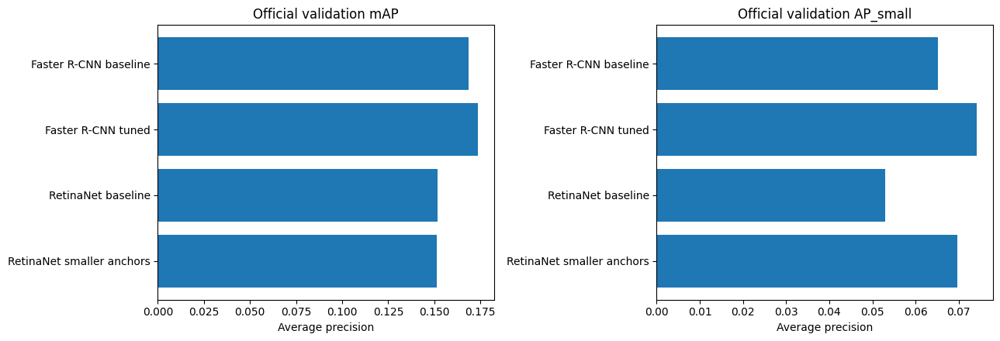

In [25]:

metrics = pd.DataFrame(
    [
        {
            "candidate": "Faster R-CNN baseline",
            "model": "Faster R-CNN",
            "mAP": 0.168492,
            "AP50": 0.343421,
            "AP_small": 0.065114,
            "AP_medium": 0.164735,
            "AP_large": 0.319328,
        },
        {
            "candidate": "Faster R-CNN tuned",
            "model": "Faster R-CNN",
            "mAP": 0.173837,
            "AP50": 0.350219,
            "AP_small": 0.074241,
            "AP_medium": 0.168660,
            "AP_large": 0.319824,
        },
        {
            "candidate": "RetinaNet baseline",
            "model": "RetinaNet",
            "mAP": 0.151721,
            "AP50": 0.302021,
            "AP_small": 0.052879,
            "AP_medium": 0.158991,
            "AP_large": 0.265586,
        },
        {
            "candidate": "RetinaNet smaller anchors",
            "model": "RetinaNet",
            "mAP": 0.151295,
            "AP50": 0.334956,
            "AP_small": 0.069745,
            "AP_medium": 0.141452,
            "AP_large": 0.254822,
        },
    ]
)

metrics.to_csv(
    ANCHOR_OUT / "original_official_validation_metrics.csv",
    index=False,
)

display(metrics)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, key in zip(axes, ["mAP", "AP_small"]):
    ax.barh(metrics["candidate"], metrics[key])
    ax.set_title(f"Official validation {key}")
    ax.set_xlabel("Average precision")
    ax.invert_yaxis()

fig.tight_layout()

metric_plot = ANCHOR_OUT / "anchor_based_ap_comparison.png"

fig.savefig(metric_plot, dpi=160)
display(fig)
plt.close(fig)

## 6. Training dynamics and configurations

We visualize genuine saved training histories when available, and retain the original experiment configuration for each detector.

In [26]:

LOGS = ART / "training_logs"
LOGS.mkdir(parents=True, exist_ok=True)

LOG_MAP = {
    "YOLO11": "yolo11.csv",
    "RT-DETR": "rtdetr.csv",
    "Faster R-CNN": "faster_rcnn.csv",
    "RetinaNet": "retinanet.csv",
}

CONFIG_HINTS = {
    "YOLO11": "configs/anchor_free/af1_imgsz1152.yaml",
    "RT-DETR": "configs/query_based/qb0_rtdetr_l_1152.yaml",
}

logs = {}

for name, filename in LOG_MAP.items():
    path = LOGS / filename

    if path.is_file():
        frame = pd.read_csv(path)
        frame.columns = frame.columns.str.strip()

        logs[name] = frame

        numeric = frame.select_dtypes(include="number")

        cols = [
            c
            for c in numeric
            if c.lower() not in ("epoch", "step")
            and numeric[c].notna().sum() > 1
        ][:6]

        if cols:
            fig, axs = plt.subplots(
                len(cols),
                1,
                figsize=(10, 2.5 * len(cols)),
                squeeze=False,
            )

            for ax, col in zip(axs[:, 0], cols):
                ax.plot(
                    frame["epoch"]
                    if "epoch" in frame
                    else np.arange(len(frame)),
                    numeric[col],
                )

                ax.set_title(f"{name} — {col}")
                ax.grid(alpha=0.3)

            fig.tight_layout()

            fig.savefig(
                OUT / (
                    f"training_"
                    f"{re.sub(r'[^a-z0-9]+', '_', name.lower())}.png"
                ),
                dpi=130,
            )

            display(fig)
            plt.close(fig)

    else:
        print(f"MISSING TRAINING HISTORY: {name}: {path}")

print("Available training histories:", list(logs))

MISSING TRAINING HISTORY: YOLO11: D:\UCU\ai\hw2\cv-object-detection\artifacts\training_logs\yolo11.csv
MISSING TRAINING HISTORY: RT-DETR: D:\UCU\ai\hw2\cv-object-detection\artifacts\training_logs\rtdetr.csv
MISSING TRAINING HISTORY: Faster R-CNN: D:\UCU\ai\hw2\cv-object-detection\artifacts\training_logs\faster_rcnn.csv
MISSING TRAINING HISTORY: RetinaNet: D:\UCU\ai\hw2\cv-object-detection\artifacts\training_logs\retinanet.csv
Available training histories: []


In [27]:

LOGDIR = LOGS
LOGDIR.mkdir(parents=True, exist_ok=True)

import csv
import collections


def collect_output_text(path):
    nb = nbformat.read(path, as_version=4)
    parts = []

    for ci, cell in enumerate(nb.cells):
        for oi, o in enumerate(cell.get("outputs", [])):
            t = o.get("text", "")

            if isinstance(t, list):
                t = "".join(t)

            data = o.get("data", {})

            if not t and "text/plain" in data:
                t = data["text/plain"]

            if isinstance(t, list):
                t = "".join(t)

            if t:
                parts.append((ci, oi, str(t)))

    return parts


notebook_text = {
    name: collect_output_text(path)
    for name, path in SRC.items()
}

path_hints = {}

for name in ["Faster R-CNN", "RetinaNet"]:
    hints = []

    for ci, oi, t in notebook_text[name]:
        for line in t.splitlines():
            if re.search(
                r"(train_folds\.csv|results\.csv|history\.csv|metrics\.csv|"
                r"retinanet_runs|faster_rcnn_runs|runs\\)",
                line,
                re.I,
            ):
                line = line.strip()

                if line and line not in hints:
                    hints.append(line[:350])

    path_hints[name] = hints

    print(
        "\n",
        name,
        "— saved training-file / run-directory references:",
    )

    for h in hints[:15]:
        print("  ", h)


HISTORY_NAMES = {
    "Faster R-CNN": [
        "faster_rcnn.csv",
        "faster-rcnn.csv",
        "train_folds.csv",
        "faster_rcnn_history.csv",
    ],
    "RetinaNet": [
        "retinanet.csv",
        "retina_net.csv",
        "retinanet_history.csv",
        "results.csv",
    ],
}


def valid_history(frame):
    if len(frame) < 2:
        return False

    numeric = frame.select_dtypes(include="number")

    meaningful = [
        c
        for c in numeric
        if re.search(r"loss|map|ap|precision|recall|lr", c, re.I)
        and numeric[c].notna().sum() >= 2
    ]

    return bool(meaningful)


histories = {}
history_sources = {}

for name, names in HISTORY_NAMES.items():
    candidates = [LOGDIR / f for f in names]

    tag = "faster" if name == "Faster R-CNN" else "retina"

    candidates += sorted(
        p
        for p in LOGDIR.rglob("*.csv")
        if tag in str(p).lower()
    )

    for path in dict.fromkeys(candidates):
        if not path.is_file():
            continue

        try:
            frame = pd.read_csv(path)
        except Exception:
            continue

        if valid_history(frame):
            histories[name] = frame
            history_sources[name] = str(path.relative_to(ROOT))
            break


for name in ["Faster R-CNN", "RetinaNet"]:
    if name in histories:
        continue

    notebook = nbformat.read(SRC[name], as_version=4)

    for ci, cell in enumerate(notebook.cells):
        for oi, o in enumerate(cell.get("outputs", [])):
            data = o.get("data", {})
            html = data.get("text/html", "")

            if isinstance(html, list):
                html = "".join(html)

            if not html or "<table" not in html:
                continue

            try:
                tables = pd.read_html(io.StringIO(html))
            except Exception:
                continue

            for table in tables:
                table.columns = [str(c) for c in table.columns]

                if (
                    valid_history(table)
                    and any(
                        str(col).lower()
                        in ("epoch", "step", "global_step")
                        for col in table.columns
                    )
                    and re.search(
                        r"loss|train",
                        " ".join(table.columns),
                        re.I,
                    )
                ):
                    histories[name] = table
                    history_sources[name] = (
                        f"{SRC[name].name} cell {ci}, "
                        f"output {oi} HTML table"
                    )
                    break

            if name in histories:
                break

        if name in histories:
            break


history_plots = {}

for name, h in histories.items():
    numeric = h.select_dtypes(include="number")

    cols = [
        c
        for c in numeric
        if re.search(r"loss|map|ap|precision|recall|lr", c, re.I)
        and numeric[c].notna().sum() >= 2
    ][:8]

    if not cols:
        continue

    x = (
        h["epoch"]
        if "epoch" in h
        and pd.api.types.is_numeric_dtype(h["epoch"])
        else np.arange(len(h))
    )

    fig, axes = plt.subplots(
        len(cols),
        1,
        figsize=(9, 2.5 * len(cols)),
        squeeze=False,
    )

    for ax, col in zip(axes[:, 0], cols):
        ax.plot(x, numeric[col])
        ax.set_title(f"{name}: {col}")
        ax.grid(alpha=0.25)

    fig.tight_layout()

    dest = ANCHOR_OUT / (
        name.lower().replace(" ", "_").replace("-", "_")
        + "_training_curves.png"
    )

    fig.savefig(dest, dpi=130)
    display(fig)
    plt.close(fig)

    history_plots[name] = dest

    print(
        "Recovered real training history for",
        name,
        "from",
        history_sources[name],
    )


for name in ["Faster R-CNN", "RetinaNet"]:
    if name not in histories:
        print(
            "NOT RECOVERED:",
            name,
            "— no multi-step training history found "
            "in saved notebook outputs or CSVs.",
        )


for model_name, history in histories.items():
    if model_name not in logs:
        logs[model_name] = history

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)



 Faster R-CNN — saved training-file / run-directory references:
   train_folds.csv: 1.80 MiB
   Fold assignments: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\faster_rcnn_baseline_fold0\train_folds.csv
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\tmpc8yrqnvg\last.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\tmpc8yrqnvg\last.previous.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_e5dcc22f4476_fold0\last.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_f15f44c2db51_fold0\last.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_d7fa2d50b82b_fold0\last.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\last.pt
   Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_f15f44c2db51_fold1\last.pt
   Loaded checkpoint: H:\

## 7. Weights & Biases experiment tracking

We log per-model configurations, available training histories, validation figures, and measured diagnostics. For the anchor-based models, figures are from the executed experiment notebooks rather than newly generated inference.

In [28]:

from getpass import getpass

WANDB_PROJECT = "cv-object-detection-hw2-visualization"
WANDB_ENTITY = None

key = os.environ.get("WANDB_API_KEY", "").strip()

if not key:
    key = getpass(
        "W&B API key (hidden; not saved in notebook): "
    ).strip()

if not key:
    raise RuntimeError(
        "W&B API key is required to meet the rubric."
    )

if not wandb.login(key=key, relogin=True):
    raise RuntimeError("W&B login failed")

del key

print("W&B authenticated")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.


wandb: [wandb.login()] Using explicit session credentials for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: C:\Users\Admin\_netrc
wandb: Currently logged in as: d-shevchuk-pn (d-shevchuk-pn-ukrainian-catholic-university) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


W&B authenticated


In [29]:

wandb_urls = {}

for name in ["Faster R-CNN", "RetinaNet", "YOLO11", "RT-DETR"]:
    if name in MODEL_SPECS:
        spec = MODEL_SPECS[name]
        config_path = ROOT / CONFIG_HINTS[name]

        config = (
            yaml.safe_load(config_path.read_text(encoding="utf-8"))
            if config_path.exists()
            else {}
        )

        config = dict(config or {})

        config.update(
            {
                "model_family": name,
                "checkpoint": str(spec["path"].relative_to(ROOT)),
                "validation_images": len(chosen),
                "confidence_threshold": CONF,
                "diagnostic_iou": 0.5,
                "diagnostic_protocol": "sample matching; not COCO AP",
                "evidence_source": "direct validation inference",
            }
        )

    else:
        config = {
            "model_family": name,
            "experiment_notebook": SRC[name].name,
            "evaluation_split": "official validation",
            "evidence_source": "saved experiment notebook outputs",
            "training_history_available": name in logs,
        }

    run_name = (
        name.lower().replace(" ", "_").replace("-", "_")
        + "-visualization"
    )

    with wandb.init(
        project=WANDB_PROJECT,
        entity=WANDB_ENTITY,
        name=run_name,
        job_type="visualization",
        config=config,
        reinit=True,
    ) as run:
        if name in records:
            model_df = df[df["model"] == name]

            for status, count in model_df["status"].value_counts().items():
                run.summary[f"diagnostics/{status}"] = int(count)

            for model, p in overlay_paths:
                if model == name:
                    run.log(
                        {
                            "validation/bounding_boxes": wandb.Image(str(p))
                        }
                    )

            for p in [
                OUT / "failure_by_class.png",
                OUT / "failure_by_size.png",
            ]:
                if p.exists():
                    run.log(
                        {
                            "diagnostics/" + p.stem: wandb.Image(str(p))
                        }
                    )

        if name in ["Faster R-CNN", "RetinaNet"]:
            for row in metrics.loc[
                metrics.model.eq(name)
            ].to_dict("records"):
                key = (
                    row["candidate"]
                    .lower()
                    .replace(" ", "_")
                    .replace("-", "_")
                )

                for metric in [
                    "mAP",
                    "AP50",
                    "AP_small",
                    "AP_medium",
                    "AP_large",
                ]:
                    run.summary[
                        f"official_val/{key}/{metric}"
                    ] = float(row[metric])

            run.log(
                {
                    "official_val/comparison": wandb.Image(
                        str(metric_plot)
                    )
                }
            )

            for p, cell_i, out_i in extracted[name]:
                run.log(
                    {
                        "validation/saved_evaluation_figure": wandb.Image(
                            str(p),
                            caption=(
                                f"{SRC[name].name}, "
                                f"cell {cell_i}, output {out_i}"
                            ),
                        )
                    }
                )

        if name in logs:
            history = logs[name].select_dtypes(include="number")

            for step, (_, row) in enumerate(history.iterrows()):
                values = {
                    f"training/{col}": float(value)
                    for col, value in row.items()
                    if pd.notna(value) and np.isfinite(value)
                }

                if values:
                    run.log(values, step=step)

        if name in history_plots:
            run.log(
                {
                    "training/curves": wandb.Image(
                        str(history_plots[name])
                    )
                }
            )

        if name == "YOLO11":
            for p in [pca_path, tsne_path]:
                if p is not None and p.exists():
                    run.log(
                        {
                            "features/" + p.stem: wandb.Image(str(p))
                        }
                    )

        wandb_urls[name] = run.url
        print(name, run.url)

print("W&B runs:", wandb_urls)

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Faster R-CNN https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/jccyyq7u


official_val/faster_r_cnn_baseline/AP50,0.34342
official_val/faster_r_cnn_baseline/AP_large,0.31933
official_val/faster_r_cnn_baseline/AP_medium,0.16473
official_val/faster_r_cnn_baseline/AP_small,0.06511
official_val/faster_r_cnn_baseline/mAP,0.16849
official_val/faster_r_cnn_tuned/AP50,0.35022
official_val/faster_r_cnn_tuned/AP_large,0.31982
official_val/faster_r_cnn_tuned/AP_medium,0.16866
official_val/faster_r_cnn_tuned/AP_small,0.07424
official_val/faster_r_cnn_tuned/mAP,0.17384


RetinaNet https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/usjgtm3j


official_val/retinanet_baseline/AP50,0.30202
official_val/retinanet_baseline/AP_large,0.26559
official_val/retinanet_baseline/AP_medium,0.15899
official_val/retinanet_baseline/AP_small,0.05288
official_val/retinanet_baseline/mAP,0.15172
official_val/retinanet_smaller_anchors/AP50,0.33496
official_val/retinanet_smaller_anchors/AP_large,0.25482
official_val/retinanet_smaller_anchors/AP_medium,0.14145
official_val/retinanet_smaller_anchors/AP_small,0.06975
official_val/retinanet_smaller_anchors/mAP,0.1513


YOLO11 https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/xd1r4x7t


diagnostics/FN,251
diagnostics/FP,894
diagnostics/TP,1105


RT-DETR https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/ee087yn8


diagnostics/FN,182
diagnostics/FP,2925
diagnostics/TP,1174


W&B runs: {'Faster R-CNN': 'https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/jccyyq7u', 'RetinaNet': 'https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/usjgtm3j', 'YOLO11': 'https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/xd1r4x7t', 'RT-DETR': 'https://forge.coreweave.com/wandb/d-shevchuk-pn-ukrainian-catholic-university/cv-object-detection-hw2-visualization/runs/ee087yn8'}


## 8. Interpretation

We evaluate each architecture on its observed strengths and failure modes, rather than interpreting model family alone as a performance guarantee.

**Anchor-based detectors.** On official validation, tuning Faster R-CNN increases mAP from 0.1685 to 0.1738 and AP for small objects from 0.0651 to 0.0742. For RetinaNet, smaller anchors increase AP50 and AP for small objects, while overall mAP remains approximately unchanged (0.1517 vs 0.1513). This suggests that improving candidate coverage for small objects can involve trade-offs across object scales and IoU thresholds.

**Object scale.** Our EDA and architectural experiments indicate that small objects and crowded scenes are important sources of detection errors. We examine these effects in the class/size diagnostic charts above. The charts show the selected validation sample and should not be presented as official dataset-wide AP.

**Representations.** We inspect whether the YOLO11 PCA and t-SNE plots show separation by object class and whether TP and FP detections overlap. The visualizations are exploratory and do not establish classification quality on their own.

**Comparability.** We distinguish official-validation AP from the sampled TP/FP/FN diagnostics and from saved evaluation figures. We report only training curves that are backed by saved histories.

## 9. Reproducibility and output summary

We summarize the evidence produced for each detector and provide W&B links.

In [30]:

summary = pd.DataFrame(
    [
        {
            "model": name,
            "training_history": name in logs,
            "new_validation_inference": name in MODELS,
            "saved_evaluation_figures": len(extracted.get(name, [])),
            "sample_bounding_box_diagnostics": name in records,
            "official_validation_metrics": name in [
                "Faster R-CNN",
                "RetinaNet",
            ],
            "wandb_run": wandb_urls.get(name, ""),
        }
        for name in [
            "Faster R-CNN",
            "RetinaNet",
            "YOLO11",
            "RT-DETR",
        ]
    ]
)

display(summary)

summary.to_csv(
    OUT / "visualization_evidence_summary.csv",
    index=False,
)

print("Generated figures:", OUT)
print("Check W&B project visibility before submitting the link.")

,model,training_history,new_validation_inference,saved_evaluation_figures,sample_bounding_box_diagnostics,official_validation_metrics,wandb_run
0,Faster R-CNN,False,False,3,False,True,https://forge.coreweave.com/wandb/d-shevchuk-p...
1,RetinaNet,False,False,3,False,True,https://forge.coreweave.com/wandb/d-shevchuk-p...
2,YOLO11,False,True,0,True,False,https://forge.coreweave.com/wandb/d-shevchuk-p...
3,RT-DETR,False,True,0,True,False,https://forge.coreweave.com/wandb/d-shevchuk-p...


Generated figures: D:\UCU\ai\hw2\cv-object-detection\artifacts\visualization
Check W&B project visibility before submitting the link.
